# Exemples cours introduction explicabilité machine learning
ce notebook permet d'illustrer le cours avec des exemples. 
Dans ce cadre, les données et le modèle sont travaillés très rapidement.
<br />

Les data source proviennent de [ERA5](https://cds.climate.copernicus.eu/datasets/reanalysis-era5-single-levels?tab=download)






In [25]:
#Import des librairies
import pandas as pd
import numpy as np
import shap
from shapash.explainer.smart_explainer import SmartExplainer
from sklearn.model_selection import train_test_split
import catboost
import lightgbm
from sklearn.inspection import PartialDependenceDisplay

import warnings
warnings.filterwarnings("ignore")

import plotly
plotly.io.renderers.default = 'png'


In [26]:
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)
pd.set_option('display.width', 1000)

## Import du dataset

In [27]:
df = pd.read_csv("../../data/era5_sample.csv")

In [28]:
df['valid_time'] = pd.to_datetime(df['valid_time'])
df['hour'] = df['valid_time'].dt.hour
df['wind_speed'] = np.sqrt(df['u10']**2 + df['v10']**2) * 3.6 #en km/h
df['t2m'] = df['t2m'] - 273.15 #en celsius

In [29]:
df.head(1)

,Unnamed: 0,time,step,latitude,longitude,number,surface,valid_time,d2m,t2m,ssrd,u10,v10,sp,tp,hour,wind_speed
0,8972251,2024-09-11,0 days 12:00:00,11.65,29.98,0,0.0,2024-09-11 12:00:00,296.1538,30.27505,18037366.0,0.476963,1.179552,93508.81,0.000489,12,4.580407


## Modélisation

In [30]:
features = ['latitude', 'longitude', 'd2m', 't2m', 'ssrd', 'sp', 'tp', 'hour', 'wind_speed']

In [31]:
df_reduit = df[features].copy()
df_reduit.dropna(inplace=True)

In [32]:
df_reduit["target"]=df_reduit["wind_speed"]
y = df_reduit["target"]
X = df_reduit.drop(["target", "wind_speed"], axis=1)

In [33]:
Xtrain, Xtest, ytrain, ytest = train_test_split(
    X, y, train_size=0.75, random_state=1
)

model = catboost.CatBoostRegressor()
model.fit(Xtrain, ytrain, verbose=False)

CatBoostRegressor(loss_function='RMSE')

## Explicabilité

In [34]:
feature_dict = {
    'd2m': 'Température point de rosée',  
    't2m': 'Température',  
    'ssrd': 'Rayonnement solaire ',
    'sp': 'Pression',  
    'tp': 'Précipitations',  
}

In [35]:
#Init Shapash
xpl = SmartExplainer(model=model, features_dict=feature_dict)

In [36]:
# Compilation de Shapash
xpl.compile(
    x=Xtest,    
    y_target = ytest,
)

INFO: Shap explainer type - <shap.explainers._tree.TreeExplainer object at 0x12b046a20>


In [37]:
#Lancement de la webapp
app=xpl.run_app(port=8080)

INFO:root:Your Shapash application run on http://PMP01087:8080/
INFO:root:Use the method .kill() to down your app.


In [38]:
app.kill()

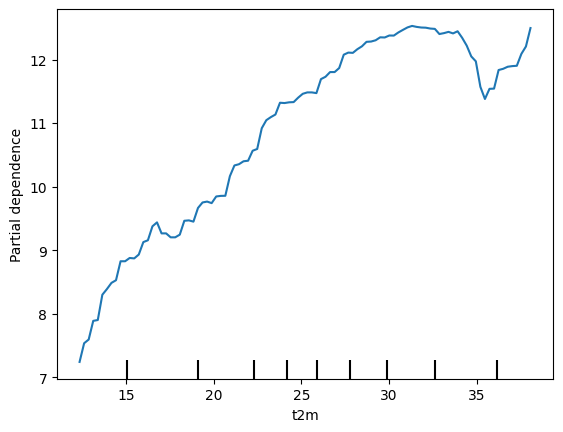

In [39]:
# PDP par sklearn
features_info = {
    # features of interest
    "features": ["t2m"]}

display = PartialDependenceDisplay.from_estimator(
    model,
    Xtest,
    **features_info,    
)

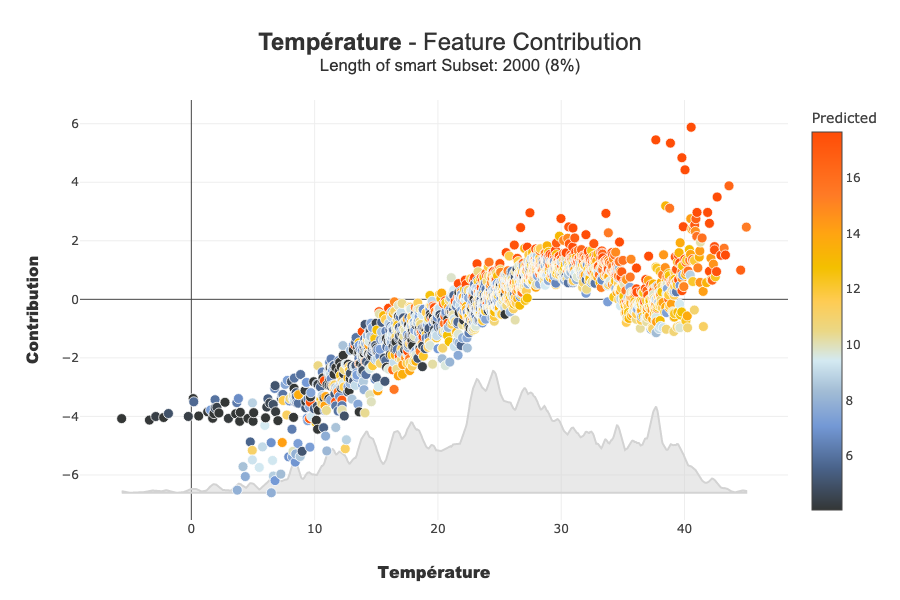

In [40]:
xpl.plot.contribution_plot(col="t2m")

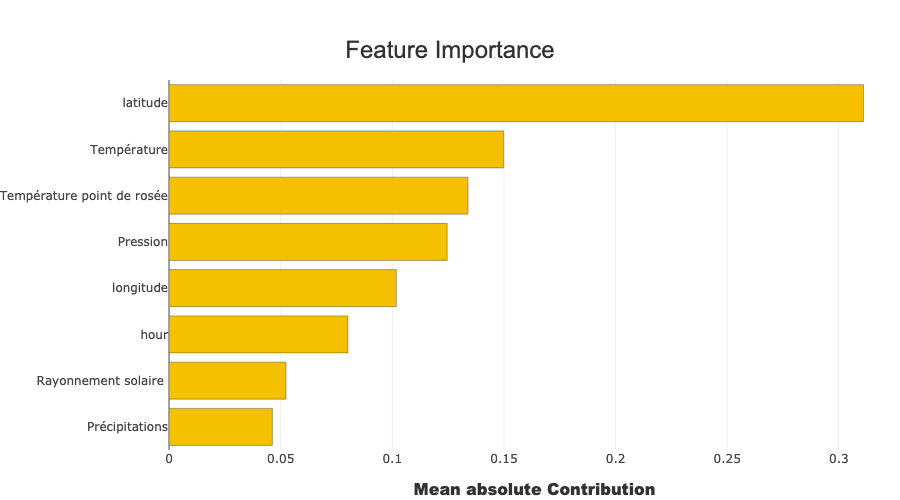

In [41]:
xpl.plot.features_importance()

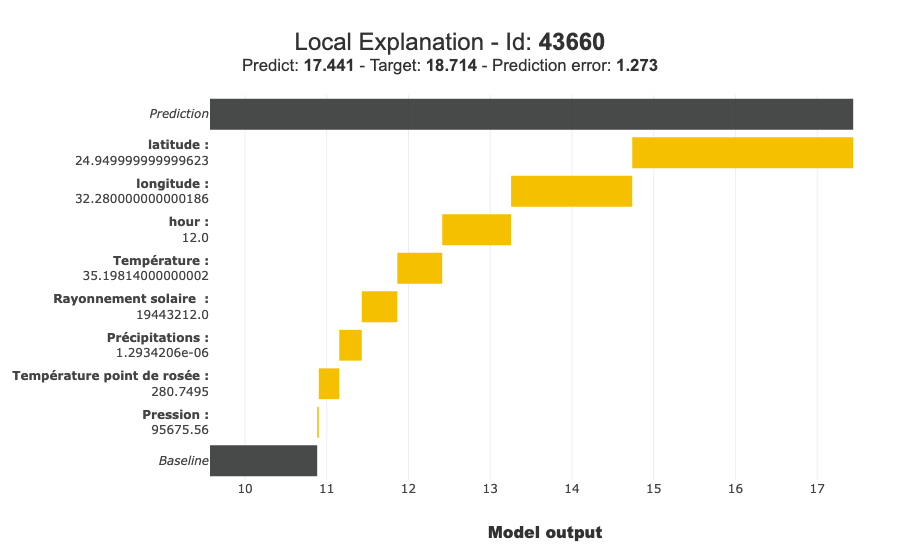

In [47]:
xpl.plot.local_plot(index=43660, plot_type='waterfall', waterfall_xaxis_start='auto')

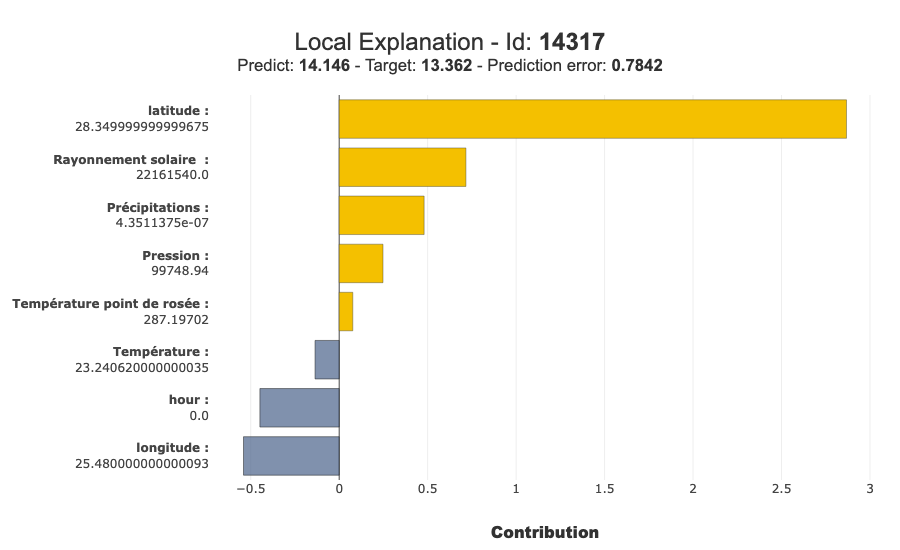

In [48]:
xpl.plot.local_plot(index=14317)

In [44]:
model_lgb = lightgbm.LGBMRegressor()
model_lgb.fit(Xtrain, ytrain)

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000242 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1773
[LightGBM] [Info] Number of data points in the train set: 75000, number of used features: 8
[LightGBM] [Info] Start training from score 10.883168


,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,learning_rate,0.1
,n_estimators,100
,subsample_for_bin,200000
,objective,None
,class_weight,None
,min_split_gain,0.0
,min_child_weight,0.001
,min_child_samples,20


In [45]:
xpl_lgb = SmartExplainer(model=model_lgb)

xpl_lgb.compile(
    x=Xtest,    
    y_target = ytest
)

INFO: Shap explainer type - <shap.explainers._tree.TreeExplainer object at 0x121558710>


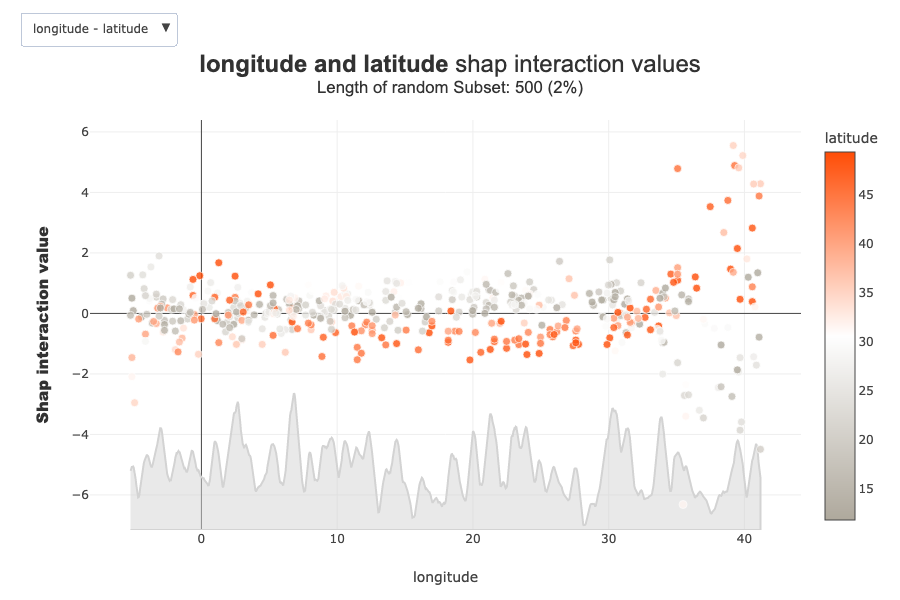

In [46]:
xpl.plot.top_interactions_plot(nb_top_interactions=2)